# E119 · Would a more centrist or a more progressive nominee have done better? What the data can and cannot say

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real, and nothing new: E94's US House and Senate races of 2018 and 2022 (certified results from the **FEC**, public domain; partisan lean from **FiveThirtyEight**, CC BY 4.0), E118's caucus rosters and endorsement lists dated before each election (**Wikipedia** revisions and **Internet Archive** captures, CC BY-SA 4.0; facts only) and its build log, and the 2018 **Cooperative Congressional Election Study** (Ansolabehere, Schaffner and Luks; Harvard Dataverse, as redistributed with Lopez-Martin, Phillips and Gelman's MRP case study) |
| **You will learn** | Writing a "what if" question as an **estimand** with potential outcomes, and telling it apart from a neighbouring question that sounds the same · a **causal graph** that names what stands in the way · **auditing** the data a question needs against the data that exist · a Bayesian regression of the margin with Student-t errors, and why its interval is not the uncertainty that matters · from a margin to a **probability of winning** · **sensitivity to an unmeasured confounder**, benchmarked against a measured one · **simulated elections** in which a sensible adjustment gets the answer wrong · a **power analysis by simulation** for a close-primary regression discontinuity |

## The question

E118 tested a claim heard after every election: moderate Democrats beat their polls, the left fell short of
theirs, and ideology is the reason. With labels dated before the election it found no gap. It is tempting
to read that as "ideology does not matter for winning". It says nothing of the kind, and this notebook is
about the question it leaves open, the one a party, a donor or a primary voter actually faces: **in a given
race, would nominating a more centrist Democrat, or a more progressive one, have produced a better result
in November?**

There is good evidence that the answer is sometimes yes. Canes-Wrone, Brady and Cogan (2002) found that
House members whose roll-call voting was out of step with their districts won smaller shares of the vote.
Hall (2015) went further, to the counterfactual itself. He compared House primaries from 1980 to 2010 in
which a more extreme candidate narrowly beat a more moderate one with primaries in which the extremist
narrowly lost, measuring ideology from the donors who gave to each candidate. Close primaries are nearly
coin flips, so the two kinds of district are alike in everything but the nominee: a regression
discontinuity. When the extremist won, the party's general-election vote share fell by about 9 to 13
points and its chance of winning the seat by 35 to 54 percentage points.

Those are answers for the elections and the ideology measure that Hall studied. Here we ask whether the
data in this repository, built for E94 and E118, can give one for 2018 and 2022 and for the left and
centre lists that E118 dated. The short answer is no, and the useful part is why, and what it would take.

| part | question | tool |
|---|---|---|
| 1 | What exactly is being asked, and how does it differ from E118's question? | potential outcomes, a causal graph |
| 2 | What does the repository hold for it? | an audit: races, lean, polls, primaries, scores, lists, a survey |
| 3 | What does the comparison a commentator would make show? | margins by list, and where each list's nominees ran |
| 4 | What does a model with district lean and incumbency say? | a Bayesian regression with Student-t errors, a probability of winning |
| 5 | How strong would a hidden confounder have to be to change the answer? | omitted-variable sensitivity, benchmarked against lean |
| 6 | Can a sensible comparison get the sign wrong? | simulated elections with a known answer |
| 7 | What data would answer the question, and how much? | the designs, and a power analysis for close primaries |

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import json
import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from matplotlib.lines import Line2D
from scipy import stats

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub; nothing here uses JAX (see E89, E118)

RANDOM_SEED = 119
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
plt.rcParams.update({"axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9})
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
T_START = time.time()

INK, MUTED, LIGHT = "#222222", "#8a8a8a", "#d9d9d9"
LEFT_C, CEN_C, D_C, R_C = "#7b3294", "#e08e0b", "#2166ac", "#c0392b"
LEFT = ["cpc", "jd", "our_revolution", "bnc", "dsa_member"]                               # as in E118
CENTRE = ["ndc", "blue_dog", "blue_dog_site", "blue_dog_pac", "newdem_fund", "newdem_watch"]
ENDORSE = {"jd": "Justice Democrats", "bnc": "Brand New Congress", "our_revolution": "Our Revolution",
           "blue_dog_pac": "Blue Dog PAC", "newdem_fund": "NewDem Action Fund"}

## 1 · The question, written down

For a race $i$, write $Y_i(\mathrm{c})$ for the certified two-party margin (Democrat minus Republican, in
points) that the race would produce if the Democratic nominee were on a centre list, and $Y_i(\mathrm{l})$
for the margin with a nominee on a left list. These are **potential outcomes** (Rubin's framing): both
are defined for every race, and at most one of them is ever seen. The question is about their difference,

$$
\tau = \mathbb{E}\left[\,Y_i(\mathrm{c}) - Y_i(\mathrm{l}) \;\middle|\; \text{both kinds of candidate were real options in race } i\,\right],
$$

and, since parties care about seats more than points, about the difference in the chance of winning,
$\Pr(Y_i(\mathrm{c}) > 0) - \Pr(Y_i(\mathrm{l}) > 0)$. The condition matters. A seat where no left-list
candidate ran in the primary has no left-list alternative to compare with, and averaging over such races
answers a question nobody faced.

E118's outcome was different: the margin minus the final poll average, $Y_i(d) - P_i(d)$ for the nominee
$d$ who actually ran. Its contrast between the lists is

$$
\tau_{\text{poll}} = \bigl[Y(\mathrm{c}) - P(\mathrm{c})\bigr] - \bigl[Y(\mathrm{l}) - P(\mathrm{l})\bigr]
= \tau - \bigl[P(\mathrm{c}) - P(\mathrm{l})\bigr].
$$

If voters penalise a nominee who is far from the district, the polls of that race see the penalty too,
because they ask the same voters about the same nominee. Then $P(\mathrm{c}) - P(\mathrm{l})$ is close to
$\tau$ and $\tau_{\text{poll}}$ is close to zero, whatever $\tau$ is. A null on poll error is therefore
compatible with a large ideology penalty, with none, and with one in the other direction. E118 asked
whether ideology moves candidates **off** their polls; this notebook asks whether it moves the **votes**.

The graph below names what stands between the list a nominee is on and the margin. Arrows are causal
claims, not estimates. Blue boxes are measured in the repository, red ones are not, grey ones are measured
but should not be adjusted for.

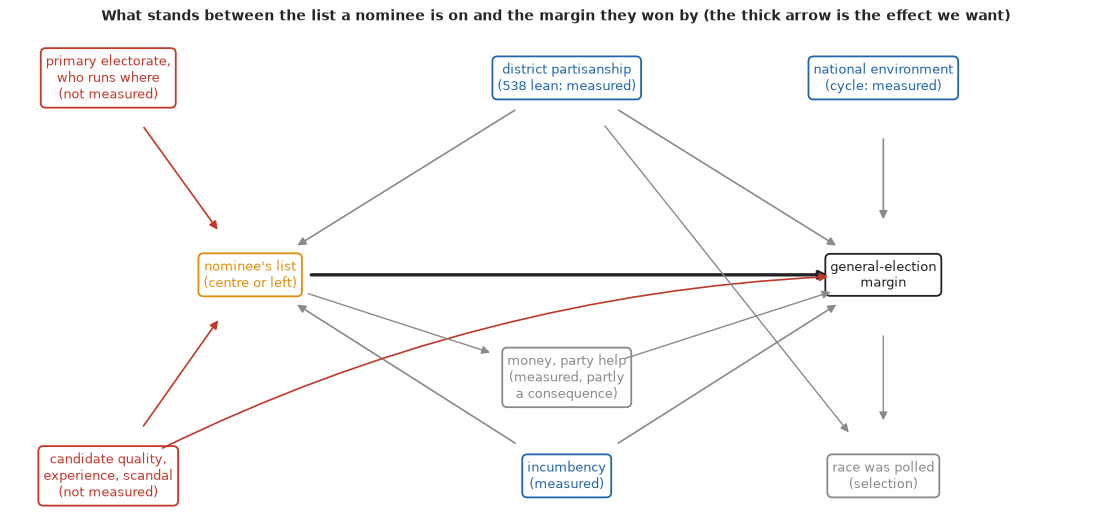

In [2]:
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")
NODES = {
    "list": (2.2, 3.0, "nominee's list\n(centre or left)", CEN_C),
    "margin": (8.0, 3.0, "general-election\nmargin", INK),
    "lean": (5.1, 5.4, "district partisanship\n(538 lean: measured)", D_C),
    "inc": (5.1, 0.55, "incumbency\n(measured)", D_C),
    "env": (8.0, 5.4, "national environment\n(cycle: measured)", D_C),
    "primary": (0.9, 5.4, "primary electorate,\nwho runs where\n(not measured)", R_C),
    "quality": (0.9, 0.55, "candidate quality,\nexperience, scandal\n(not measured)", R_C),
    "money": (5.1, 1.75, "money, party help\n(measured, partly\na consequence)", MUTED),
    "polled": (8.0, 0.55, "race was polled\n(selection)", MUTED),
}
for k, (x, y, lab, col) in NODES.items():
    ax.text(x, y, lab, ha="center", va="center", fontsize=9, color=col,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=col, lw=1.3))
EDGES = [("list", "margin", INK, 2.4, 0), ("lean", "list", MUTED, 1.2, 0), ("lean", "margin", MUTED, 1.2, 0),
         ("inc", "list", MUTED, 1.2, 0), ("inc", "margin", MUTED, 1.2, 0), ("env", "margin", MUTED, 1.2, 0),
         ("primary", "list", R_C, 1.2, 0), ("quality", "list", R_C, 1.2, 0),
         ("quality", "margin", R_C, 1.2, -0.12), ("list", "money", MUTED, 1.0, 0),
         ("money", "margin", MUTED, 1.0, 0), ("margin", "polled", MUTED, 1.0, 0), ("lean", "polled", MUTED, 1.0, 0)]
for a, b, col, lw, rad in EDGES:
    (x0, y0), (x1, y1) = NODES[a][:2], NODES[b][:2]
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=col, lw=lw, shrinkA=44, shrinkB=58 if b == "money" else 40,
                                connectionstyle=f"arc3,rad={rad}"))
ax.set_title("What stands between the list a nominee is on and the margin they won by "
             "(the thick arrow is the effect we want)", fontsize=10);

**District partisanship** is the largest arrow into the margin, and it also shapes the nomination: in a
safe Democratic seat the primary electorate is more liberal and the general election is not at stake, so a
left candidate is more likely to be nominated. **Incumbency** works the same way, since caucus rosters list
sitting members and sitting members are renominated. These two are measured. Two others are not. **Who
runs where and who votes in the primary** decides which candidates are on offer at all. **Candidate
quality** (experience, a local base, a scandal) helps a candidate win both the primary and the general,
and may be correlated with the lists, because endorsing organisations prefer candidates who can win.

Two measured things should be left out of the adjustment. **Money and party help** are partly a
consequence of the nomination (the party spends on whoever its nominee is), so adjusting for them would
remove part of the effect we want. **Whether the race was polled** is a consequence of how close it was
expected to be: restricting to polled races, as E118 had to, selects on something downstream of the
margin. This notebook uses every race.

## 2 · What the repository holds for this question

The question needs five things: the outcome in every race; district partisanship measured before the
election; the alternatives, meaning every candidate in each Democratic primary and their votes; an
ideology measure dated before the primary for every one of those candidates, losers included; and some
measure of candidate quality. We check each against the files.

In [3]:
for name in ("e94_races", "e118_ideology", "cces2018"):
    data.describe(name)
    print()
races = data.load("e94_races")
ideo = data.load("e118_ideology")
build_log = json.load(open(data.path("e118_build_log")))


def any_flag(F, cols, prefix="dx_"):
    return np.any([(F[prefix + c] == True).to_numpy() for c in cols], axis=0)  # noqa: E712  (a blank is not True)


F = races[races.cycle.isin([2018, 2022]) & races.contested & ~races.split & ~(races.d_is_ind == True)].copy()  # noqa: E712
for side in "dr":
    side_rows = ideo[ideo.side == side.upper()].drop(columns=["office", "state", "side"]).add_prefix(f"{side}x_")
    F = F.merge(side_rows, left_on=["cycle", "race"], right_on=[f"{side}x_cycle", f"{side}x_race"], how="left")
F = F[F.dx_name.notna() & ~(F.dx_multi_cands == True)].reset_index(drop=True)  # noqa: E712
F["m"] = 100 * (2 * F.dem2 - 1)                       # certified two-party margin, D minus R, points
F["left"], F["centre"] = any_flag(F, LEFT), any_flag(F, CENTRE)
F["bucket"] = np.select([F.left & F.centre, F.left, F.centre], ["both", "left", "centre"], "no list")
for s in "dr":   # incumbency by who was in office on the eve, as in E118
    F[f"{s}_inc"] = (F[f"{s}x_in_office_on_eve"].fillna(False).astype(bool)
                     & (F[f"{s}x_incumbent"].fillna(False).astype(bool) | (F.office == "H"))).astype(int)
F["open_choice"] = F.d_inc == 0                        # the party picked a nominee who did not hold the seat
F["polled"] = F.dx_polled.astype(bool)

all_rows = races[races.cycle.isin([2018, 2022])]
audit = pd.DataFrame({
    "House and Senate races": all_rows.groupby("cycle").size(),
    "both parties on the ballot, no jungle ballot": F.groupby("cycle").size(),
    "with 538 partisan lean": F[F.lean.notna()].groupby("cycle").size(),
    "with a poll (E118's sample is drawn from these)": F[F.polled].groupby("cycle").size(),
    "D nominee did not hold the seat": F[F.open_choice].groupby("cycle").size(),
}).T
print(audit.to_string())
print()
print("Democratic nominees by dated list (rows) and whether they held the seat (columns):")
print(pd.crosstab([F.cycle, F.bucket], F.d_inc.map({1: "held the seat", 0: "did not"}), margins=True).to_string())

e94_races: One row per race: cycle (2016-2026), office (H/S), state, race (e.g. PA-07, OH-S, MN-S2 for a special), region (Census), special, seat (counts toward the next Congress), lean (D-minus-R points on the margin scale: 538 lean for 2016-2022, 2 x Cook PVI for 2026; blank where the lines differ), pvi (2026), inc_party (D, R or blank for an open seat), open, d_inc, r_inc, d_id/r_id (FEC candidate IDs) and names of the top D-side and R candidates, d_is_ind (independent on the D side), contested (both sides on the ballot), split (jungle-style ballot), dem2 (D share of the two-party vote; blank for 2026), winner, rcv (ranked-choice final round used), d_votes, r_votes, *_rec_eve / *_disb_eve / *_coh_eve (receipts, disbursements, cash on hand in reports the FEC had received by the eve: 2018-11-05, 2022-11-07, 2026-11-02), *_rec_final / *_disb_final (cycle totals from weball), member and status (2026), multi_cands (2026: several candidates of one side on the November ballot, as in Louisi

The outcome and the main confounder are complete. Of 941 House and Senate races in 2018 and 2022, 861 had
both parties on the ballot without a jungle-style primary, and every one of them has a certified result and
a FiveThirtyEight partisan lean. Only 308 of them (177 and 131) have any poll, so E118's question lives in a
third of the races, while this one can use all of them. In 512 races the Democratic nominee did not hold
the seat: these are the nominations the party could have made differently without unseating a member.

The lists cover 152 left-list nominees, 176 centre-list nominees and 25 on both. Among nominees who did
not hold the seat, there are 43 on a left list (34 in 2018 and 9 in 2022) and 67 on a centre list. Most
nominees on either list held the seat (109 of 152 and 109 of 176), so most of the labels are caucus
memberships of sitting members.

In [4]:
D_ = ideo[(ideo.side == "D") & ideo.cycle.isin([2018, 2022])]
score = pd.DataFrame({
    "nominees": D_.groupby("cycle").size(),
    "served in Congress before": D_.groupby("cycle").served_before.sum(),
    "DW-NOMINATE dated before the election": D_.groupby("cycle").nominate_dim1.apply(lambda s: s.notna().sum()),
    "DW-NOMINATE, today's file": D_.groupby("cycle").nominate_dim1_posthoc.apply(lambda s: s.notna().sum()),
    "...of nominees who had not served": D_[~D_.served_before.astype(bool)].groupby("cycle").nominate_dim1_posthoc.apply(
        lambda s: s.notna().sum()),
}).T
print(score.to_string())
print()
rows = []
for key, lab in ENDORSE.items():
    for c in (2018, 2022):
        v = build_log["checks"]["ideology_lists"].get(f"{key}_{c}")
        if v:
            rows.append({"list": lab, "cycle": c, "names on the dated list": v["listed"],
                         "matched to a November nominee": v["nominees_flagged"],
                         "matched to no nominee": v["units_matching_nobody"]})
print("Endorsement lists: who on them became a nominee (from e118_build_log)")
print(pd.DataFrame(rows).to_string(index=False))
primary_sets = [k for k, v in data.REGISTRY.items() if "primary election" in v.description.lower()
                or "primary result" in v.description.lower()]
print("\nregistered datasets that describe primary-election results:", primary_sets or "none")

cycle                                  2018  2022
nominees                                467   454
served in Congress before               205   203
DW-NOMINATE dated before the election     0   202
DW-NOMINATE, today's file               205   203
...of nominees who had not served         0     0

Endorsement lists: who on them became a nominee (from e118_build_log)
              list  cycle  names on the dated list  matched to a November nominee  matched to no nominee
 Justice Democrats   2018                       79                             23                     49
 Justice Democrats   2022                       17                             12                      5
Brand New Congress   2018                       31                              7                     23
Brand New Congress   2022                       37                             13                     22
    Our Revolution   2018                       32                             31                      1

Roll-call scores cannot describe the alternatives. DW-NOMINATE exists for every nominee who had served in
Congress and for none who had not, and a version dated before the election exists only for 2022. A roll-call
score is a record of what a member did after winning a seat, so for a challenger it does not exist, and for
an incumbent it is partly a consequence of the seat itself.

The endorsement lists show where the missing alternatives are. Of 79 names on the dated 2018 Justice
Democrats list, 23 became November nominees and 49 match no nominee; Brand New Congress has 23 of 31
unmatched in 2018 and 22 of 37 in 2022. Most of the unmatched are candidates who lost a primary, though the
build log does not record why each one failed to match. They are names only: the repository has no row
for them, no primary vote and no district partisanship joined to them. The other lists point the other way.
Our Revolution's 2018 capture names 32 people and 31 became nominees, and the Blue Dog PAC and NewDem Action
Fund lists match nominees only: the versions captured shortly before the general election list people who
had already won their primaries, so they describe winners and say nothing about whom they beat. No
registered dataset holds primary results.

The one survey in the repository is the 2018 Cooperative Congressional Election Study (CCES; now the
Cooperative Election Study), which asked respondents to place their House candidates on a seven-point
ideology scale. The codebook is not in the repository, so we check which column is which.

In [5]:
FIPS = {1: "AL", 2: "AK", 4: "AZ", 5: "AR", 6: "CA", 8: "CO", 9: "CT", 10: "DE", 11: "DC", 12: "FL", 13: "GA",
        15: "HI", 16: "ID", 17: "IL", 18: "IN", 19: "IA", 20: "KS", 21: "KY", 22: "LA", 23: "ME", 24: "MD", 25: "MA",
        26: "MI", 27: "MN", 28: "MS", 29: "MO", 30: "MT", 31: "NE", 32: "NV", 33: "NH", 34: "NJ", 35: "NM", 36: "NY",
        37: "NC", 38: "ND", 39: "OH", 40: "OK", 41: "OR", 42: "PA", 44: "RI", 45: "SC", 46: "SD", 47: "TN", 48: "TX",
        49: "UT", 50: "VT", 51: "VA", 53: "WA", 54: "WV", 55: "WI", 56: "WY"}
AT_LARGE = {"AK", "DE", "MT", "ND", "SD", "VT", "WY"}
cc = pd.read_csv(data.path("cces2018"), usecols=["inputstate", "cdid116", "HouseCand1Party", "HouseCand2Party",
                                                 "CC18_334M", "CC18_334N", "ideo5"])
cc["st"] = cc.inputstate.map(FIPS)
cc["race"] = np.where(cc.st.isin(AT_LARGE), cc.st + "-00", cc.st + "-" + cc.cdid116.astype("Int64").astype(str).str.zfill(2))


def place(s):
    """A 7-point placement, with 8 (not sure) and blanks as missing."""
    return s.where(s.between(1, 7))


cc["pM"], cc["pN"] = place(cc.CC18_334M), place(cc.CC18_334N)
print(f"CCES 2018 respondents: {len(cc):,}; congressional districts covered: {cc.race.nunique()}")
print("7-point placements (1 very liberal ... 7 very conservative; 'not sure' dropped), by the party of the candidate")
chk = []
for col_, cand in (("pM", "HouseCand1Party"), ("pN", "HouseCand2Party")):
    for party in ("Democratic", "Republican"):
        v = cc.loc[cc[cand] == party, col_].dropna()
        chk.append({"column": "CC18_334" + col_[1], "candidate": cand[:10], "candidate's party": party,
                    "placements": len(v), "mean": round(v.mean(), 2)})
print(pd.DataFrame(chk).to_string(index=False))

CCES 2018 respondents: 60,000; congressional districts covered: 436
7-point placements (1 very liberal ... 7 very conservative; 'not sure' dropped), by the party of the candidate
   column  candidate candidate's party  placements  mean
CC18_334M HouseCand1        Democratic       35764  2.85
CC18_334M HouseCand1        Republican         157  5.18
CC18_334N HouseCand2        Democratic          32  2.69
CC18_334N HouseCand2        Republican       31580  5.37


Column `CC18_334M` averages 2.85 when the first House candidate shown to the respondent is a Democrat and
5.18 when it is a Republican; `CC18_334N` is the reverse for the second candidate. We take them to be the
placements of House candidates 1 and 2, an inference from these means rather than from the codebook. That
gives a perceived ideology for every 2018 nominee, challengers included, measured by the voters whose
response the question is about. We average it by district and compare it across the lists.

In [6]:
dem1 = cc[cc.HouseCand1Party == "Democratic"].groupby("race").pM.agg(["mean", "count"])
H18 = F[(F.cycle == 2018) & (F.office == "H")].merge(dem1, left_on="race", right_index=True, how="left")
H18 = H18[H18["count"] >= 10]
print(f"2018 House races with at least 10 CCES placements of the Democratic candidate: {len(H18)} of "
      f"{int(((F.cycle == 2018) & (F.office == 'H')).sum())}")
tabc = H18.groupby("bucket").agg(races=("race", "size"), placement=("mean", "mean"), lean=("lean", "mean")).round(2)
print(tabc.loc[[b for b in ["left", "centre", "both", "no list"] if b in tabc.index]].to_string())
k = H18.bucket.isin(["left", "centre"])
Xc = np.c_[np.ones(k.sum()), (H18.bucket[k] == "centre"), H18.lean[k] / 10]
bc = np.linalg.lstsq(Xc, H18["mean"][k].to_numpy(), rcond=None)[0]
print(f"centre minus left in perceived placement, holding lean fixed (least squares): {bc[1]:+.2f}; "
      f"per 10 points of lean: {bc[2]:+.2f}")

2018 House races with at least 10 CCES placements of the Democratic candidate: 391 of 391
         races  placement   lean
bucket                          
left        81       2.74  16.00
centre      65       2.89   5.33
both         5       2.70  22.27
no list    240       3.02 -12.55
centre minus left in perceived placement, holding lean fixed (least squares): +0.11; per 10 points of lean: -0.04


Every one of the 391 contested 2018 House races in the frame has at least ten placements of its Democratic
candidate. Voters barely tell the lists apart. Left-list nominees average 2.74, centre-list nominees 2.89
and nominees on no list 3.02; holding lean fixed, centre minus left is +0.11 on a scale on which the two
parties' candidates sit about 2.5 points apart. This matters for the question. The penalty that
Canes-Wrone et al. and Hall found runs through what voters see, and by this measure the lists are a mild
contrast in voters' eyes. The survey still cannot answer the counterfactual: it covers one cycle, and
voters were never asked to place the candidate who lost the primary.

## 3 · The comparison a commentator would make

The simplest version of the question compares the average margin of centre-list nominees with that of
left-list nominees. We compute it for all list nominees and for subsets, alongside the average partisan
lean of the districts each group ran in.

             nominees  centre  left  centre margin  left margin  centre minus left  centre lean  left lean
    all list nominees     176   152           13.2         29.3              -16.1          7.7       24.3
                 2018      66    82           17.1         24.5               -7.4          5.1       16.1
                 2022     110    70           10.8         34.9              -24.0          9.3       34.0
        held the seat     109   109           21.4         43.3              -21.9         14.5       38.7
did not hold the seat      67    43           -0.2         -6.2                6.0         -3.3      -12.0

won the seat, by bucket:
m        lost  won  All
bucket                 
both        1   24   25
centre     46  130  176
left       34  118  152
no list   348  160  508
All       429  432  861


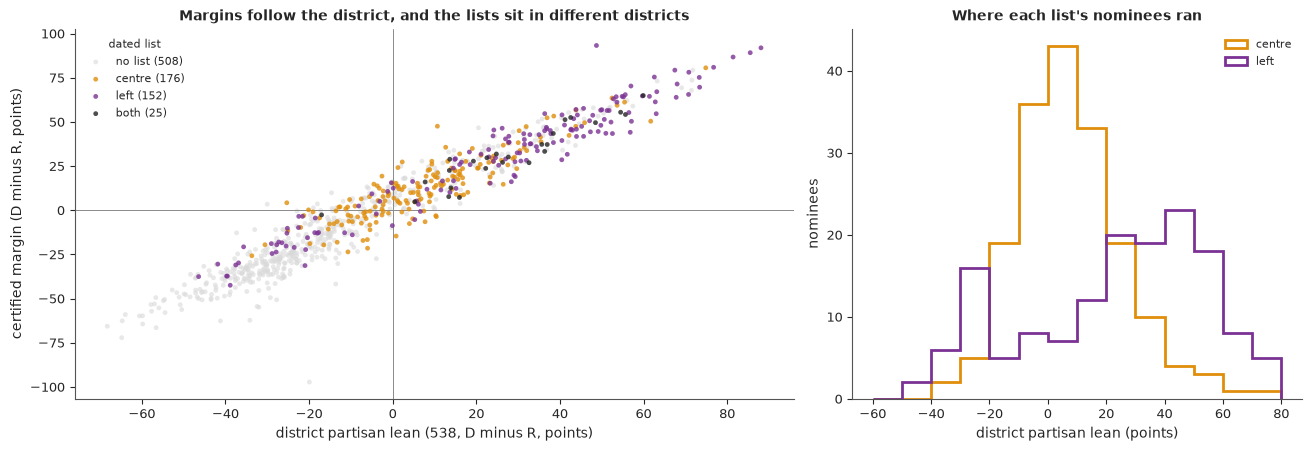

In [7]:
lab = F[F.bucket.isin(["left", "centre"])].copy()
rows = []
for name, k in (("all list nominees", lab.cycle > 0), ("2018", lab.cycle == 2018), ("2022", lab.cycle == 2022),
                ("held the seat", lab.d_inc == 1), ("did not hold the seat", lab.d_inc == 0)):
    s = lab[k]
    c, l_ = s[s.bucket == "centre"], s[s.bucket == "left"]
    rows.append({"nominees": name, "centre": len(c), "left": len(l_), "centre margin": round(c.m.mean(), 1),
                 "left margin": round(l_.m.mean(), 1), "centre minus left": round(c.m.mean() - l_.m.mean(), 1),
                 "centre lean": round(c.lean.mean(), 1), "left lean": round(l_.lean.mean(), 1)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nwon the seat, by bucket:")
print(pd.crosstab(F.bucket, F.m > 0, margins=True).rename(columns={True: "won", False: "lost"}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for b, col, z in (("no list", LIGHT, 1), ("centre", CEN_C, 3), ("left", LEFT_C, 3), ("both", INK, 3)):
    s = F[F.bucket == b]
    ax.scatter(s.lean, s.m, s=12, color=col, alpha=0.8 if b != "no list" else 0.6, edgecolor="none", zorder=z,
               label=f"{b} ({len(s)})")
ax.axhline(0, color=MUTED, lw=0.7)
ax.axvline(0, color=MUTED, lw=0.7)
ax.set_xlabel("district partisan lean (538, D minus R, points)")
ax.set_ylabel("certified margin (D minus R, points)")
ax.legend(fontsize=8, loc="upper left", title="dated list", title_fontsize=8)
ax.set_title("Margins follow the district, and the lists sit in different districts", fontsize=10)
ax = axes[1]
bins = np.arange(-60, 81, 10)
for b, col in (("centre", CEN_C), ("left", LEFT_C)):
    ax.hist(F.lean[F.bucket == b], bins=bins, histtype="step", lw=2, color=col, label=b)
ax.set_xlabel("district partisan lean (points)")
ax.set_ylabel("nominees")
ax.legend(fontsize=8)
ax.set_title("Where each list's nominees ran", fontsize=10);

Taken at face value, left-list nominees did far better: an average margin of 29.3 points against 13.2, a
gap of 16.1 points in their favour, and 118 of 152 won against 130 of 176. The lean column explains it.
Left-list nominees ran in districts that lean 24 points to the Democrats on average, centre-list nominees in
districts that lean 8. Among nominees who held the seat the gap is -21.9; among those who did not it turns
to +6.0 in the centre's favour, because there the left-list nominees ran in seats that lean 12 points to
the Republicans on average. The same data give opposite signs depending on the subset, and in each
case the sign follows the districts. The left panel shows how closely margins follow lean, and the right
panel shows that the two lists ran in different parts of the map.

## 4 · A model of the margin, with what we can measure

The obvious repair is to compare like with like: model the margin with lean, incumbency and cycle, and
read off the list effects. For race $i$ in cycle $c$ and office $o$,

$$
\begin{aligned}
y_i &\sim \text{Student-t}(\nu, \mu_i, \sigma), \\
\mu_i &= a_{c,o} + \beta_{\text{lean},c}\,\frac{\text{lean}_i}{10} + \beta_{\text{D}}\,\text{D inc}_i + \beta_{\text{R}}\,\text{R inc}_i
+ \tau_{\text{L}}\,L_i + \tau_{\text{C}}\,C_i ,
\end{aligned}
$$

where $L_i$ and $C_i$ mark a nominee on a left or a centre list (a nominee on both carries both), the
reference group is nominees on no list, and the contrast of interest is $\Delta = \tau_{\text{C}} -
\tau_{\text{L}}$. The priors: $a \sim N(0, 20)$; $\beta_{\text{lean}} \sim N(10, 3)$ per 10 points of lean,
centred on a margin that moves point for point with lean, which is what a partisan lean is built to
predict; $\beta_{\text{D}}, \beta_{\text{R}} \sim N(0, 8)$; $\tau \sim N(0, 5)$, which gives the contrast a
prior 90% interval of about ±11 points; $\sigma \sim \text{HalfNormal}(10)$ and $\nu \sim
\text{Gamma}(2, 0.1)$. The Student-t likelihood is there because some nominees run almost no campaign and
land far below their district's lean.

Under the assumptions of the graph, this adjustment would identify $\Delta$ only if lean, incumbency and
the cycle were the only paths from the list to the margin besides the effect itself. The red boxes say
they are not. We fit it anyway, to see what the best available comparison says and then how fragile it is.

In [8]:
def design(G, adjusted=True):
    groups = sorted(set(G.cycle.astype(str) + " " + G.office))
    gi = np.array([groups.index(v) for v in G.cycle.astype(str) + " " + G.office])
    cycles = [2018, 2022]
    X = {"R incumbent": G.r_inc.to_numpy(float)}
    if G.d_inc.nunique() > 1:
        X = {"D incumbent": G.d_inc.to_numpy(float)} | X
    return {"G": G, "y": G.m.to_numpy(float), "L": G.left.to_numpy(float), "C": G.centre.to_numpy(float),
            "groups": groups, "gi": gi, "ci": G.cycle.map({c: i for i, c in enumerate(cycles)}).to_numpy(),
            "lean": G.lean.to_numpy(float) / 10, "X": X, "adjusted": adjusted, "cycles": cycles}


def build_model(D):
    coords = {"group": D["groups"], "bucket": ["left", "centre"], "race": np.arange(len(D["y"]))}
    with pm.Model(coords=coords) as m:
        a = pm.Normal("a", 0.0, 20.0, dims="group")
        tau = pm.Normal("tau", 0.0, 5.0, dims="bucket")                      # against nominees on no list
        pm.Deterministic("contrast", tau[1] - tau[0])                         # centre minus left
        mu = a[D["gi"]] + tau[0] * D["L"] + tau[1] * D["C"]
        if D["adjusted"]:
            m.add_coord("cycle", D["cycles"])
            m.add_coord("x", list(D["X"]))
            b_lean = pm.Normal("b_lean", 10.0, 3.0, dims="cycle")             # points of margin per 10 points of lean
            beta = pm.Normal("beta", 0.0, 8.0, dims="x")
            mu = mu + b_lean[D["ci"]] * D["lean"] + sum(beta[j] * v for j, v in enumerate(D["X"].values()))
        sigma = pm.HalfNormal("sigma", 10.0)
        nu = pm.Gamma("nu", 2.0, 0.1)
        pm.StudentT("y", nu=nu, mu=mu, sigma=sigma, observed=D["y"], dims="race")
    return m


def diagnostics(idata):
    rh, es = az.rhat(idata.posterior), az.ess(idata.posterior)
    return {"divergences": int(idata.sample_stats["diverging"].sum()),
            "max r_hat": round(max(float(rh[v].max()) for v in rh.data_vars), 3),
            "min ESS": int(min(float(es[v].min()) for v in es.data_vars)),
            "tuning": int(idata.posterior.attrs.get("tuning_steps", -1))}


def contrast_row(c):
    c = np.asarray(c).ravel()
    return {"centre minus left": round(float(np.median(c)), 1), "90% lower": round(float(np.quantile(c, 0.05)), 1),
            "90% upper": round(float(np.quantile(c, 0.95)), 1), "P(centre ahead)": round(float((c > 0).mean()), 2)}


D_ALL = design(F)
with build_model(D_ALL):
    prior = pm.sample_prior_predictive(1000, random_seed=RANDOM_SEED)
yp = prior.prior_predictive["y"].to_numpy().ravel()
pc = prior.prior["contrast"].to_numpy().ravel()
print("prior predictive margins, 5/50/95% quantiles:", np.round(np.quantile(yp, [0.05, 0.5, 0.95]), 0))
print("prior share of margins beyond +-100 points:", round(float((np.abs(yp) > 100).mean()), 3))
print("prior 90% interval of the centre-minus-left contrast:", np.round(np.quantile(pc, [0.05, 0.95]), 1))

prior predictive margins, 5/50/95% quantiles: [-64.  -4.  66.]
prior share of margins beyond +-100 points: 0.015
prior 90% interval of the centre-minus-left contrast: [-11.5  10.9]


The prior predictive margins run from -64 to +66 points (5% to 95%), and 1.5% of them fall beyond ±100,
the edge of what a margin can be: wide, and of the right scale. We fit three versions. The **naive** one
has only cycle-and-office intercepts and the lists. The **adjusted** one adds lean and incumbency on all
861 races. The third is the adjusted model on the 512 races where **the Democratic nominee did not hold
the seat**. That subset is closer to the question: for a sitting member, "nominate someone else" means
denying a renomination, a different decision, and a member's caucus is partly a consequence of the seat.

In [9]:
FITS, DIAG = {}, {}
SAMPLES = {"naive: cycle and office only": (F, False), "adjusted: all races": (F, True),
           "adjusted: nominee did not hold the seat": (F[F.open_choice].reset_index(drop=True), True)}
for name, (G, adj) in SAMPLES.items():
    t0 = time.time()
    D = design(G, adjusted=adj)
    with build_model(D):
        FITS[name] = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.9)
    DIAG[name] = {"races": len(G), "left": int((G.bucket == "left").sum()), "centre": int((G.bucket == "centre").sum()),
                  "seconds": round(time.time() - t0, 1)} | diagnostics(FITS[name])
print(pd.DataFrame(DIAG).T.to_string())
print()
print(pd.DataFrame({k: contrast_row(v.posterior["contrast"]) for k, v in FITS.items()}).T.to_string())

                                         races   left  centre  seconds  divergences  max r_hat  min ESS  tuning
naive: cycle and office only             861.0  152.0   176.0      1.6          0.0      1.001   3490.0   400.0
adjusted: all races                      861.0  152.0   176.0      1.0          0.0      1.003   1352.0   400.0
adjusted: nominee did not hold the seat  512.0   43.0    67.0      0.9          0.0      1.003   1850.0   400.0

                                         centre minus left  90% lower  90% upper  P(centre ahead)
naive: cycle and office only                         -12.0      -16.6       -7.4             0.00
adjusted: all races                                    1.8        0.6        3.0             0.99
adjusted: nominee did not hold the seat                1.1       -1.0        3.4             0.81


All three fits are clean under nutpie: no divergences, r_hat at most 1.003, the smallest bulk ESS 1352,
400 warm-up steps, a few seconds each. Without lean the centre-minus-left contrast is -12.0 points (90%
interval -16.6 to -7.4): the commentator's comparison, with the left far ahead. With lean and incumbency it
becomes **+1.8 (+0.6 to +3.0)** on all races, and **+1.1 (-1.0 to +3.4)** among nominees who did not hold
the seat, where the posterior gives the centre list the edge with probability 0.81. Adjustment moved the
estimate by 13 points and flipped its sign. That should make us cautious about any adjustment that is
known to be incomplete, which this one is.

In [10]:
for name in ("adjusted: all races", "adjusted: nominee did not hold the seat"):
    print(name)
    print(az.summary(FITS[name], var_names=["b_lean", "beta", "tau", "sigma", "nu"], ci_prob=0.9, round_to=2).to_string())
    print()

adjusted: all races
                   mean    sd  eti90_lb  eti90_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
b_lean[2018]       9.59  0.13      9.37      9.81   2448.13   2624.14    1.0       0.00     0.00
b_lean[2022]       9.53  0.14      9.30      9.76   2268.08   2566.55    1.0       0.00     0.00
beta[D incumbent]  2.63  0.74      1.42      3.86   1422.89   1706.89    1.0       0.02     0.01
beta[R incumbent] -4.47  0.68     -5.59     -3.36   1462.55   1877.24    1.0       0.02     0.01
tau[left]          0.03  0.61     -0.99      1.00   3412.30   3050.57    1.0       0.01     0.01
tau[centre]        1.81  0.58      0.86      2.74   2945.32   2975.42    1.0       0.01     0.01
sigma              5.40  0.22      5.04      5.77   3011.88   2624.54    1.0       0.00     0.00
nu                 5.58  1.03      4.12      7.43   3075.34   2711.24    1.0       0.02     0.02

adjusted: nominee did not hold the seat
                    mean    sd  eti90_lb  eti90_ub  ess_bulk  ess_

The coefficients behave as expected. Ten points of lean are worth about 9.5 to 10.4 points of margin. A
Republican incumbent costs the Democrat 4.5 points on all races and 3.3 among the 512; a Democratic
incumbent adds 2.6. One coefficient is a warning. Among nominees who did not hold the seat, both lists beat
the no-list nominees: left-list by 2.1 (90% 0.3 to 3.8) and centre-list by 3.2 (1.7 to 4.7). A left
list and a centre list cannot both be the ideologically better choice. More likely, being on any list
marks a candidate that some organisation judged worth backing, while the no-list group includes nominees
who ran little campaign. Candidate quality enters through the label, which is the red arrow in the graph.

Next, a posterior predictive check of the adjusted model on all races, and its residuals against lean.

share of races inside their 90% posterior predictive interval: 0.89
by bucket: {'both': 0.96, 'centre': 0.85, 'left': 0.89, 'no list': 0.9}
mean residual by lean band: lean  (-100, -20]  (-20, -10]  (-10, 0]  (0, 10]  (10, 20]  (20, 100]
mean         -0.8         0.4       1.3      0.3      -1.3       -0.2
size        274.0       114.0      96.0     83.0      82.0      212.0


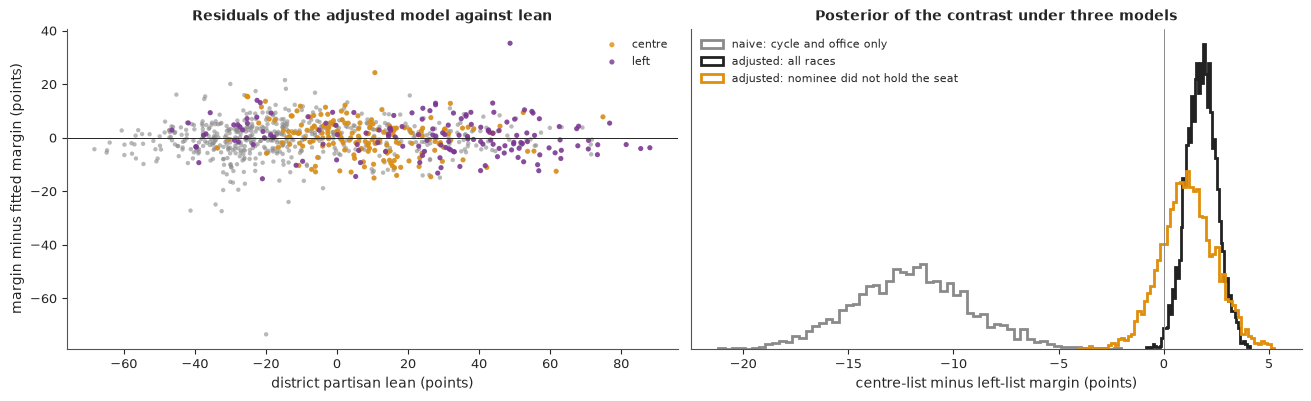

In [11]:
D = design(F)
post = FITS["adjusted: all races"].posterior
mu_hat = (post["a"].mean(("chain", "draw")).to_numpy()[D["gi"]]
          + post["b_lean"].mean(("chain", "draw")).to_numpy()[D["ci"]] * D["lean"]
          + sum(float(post["beta"].sel(x=j).mean()) * v for j, v in D["X"].items())
          + float(post["tau"].sel(bucket="left").mean()) * D["L"] + float(post["tau"].sel(bucket="centre").mean()) * D["C"])
F["resid"] = F.m - mu_hat
with build_model(D):
    ppc = pm.sample_posterior_predictive(FITS["adjusted: all races"].isel(draw=slice(None, None, 10)),
                                         random_seed=RANDOM_SEED, progressbar=False)
yrep = ppc.posterior_predictive["y"].to_numpy().reshape(-1, len(F))
cover = ((F.m.to_numpy() >= np.quantile(yrep, 0.05, 0)) & (F.m.to_numpy() <= np.quantile(yrep, 0.95, 0)))
print(f"share of races inside their 90% posterior predictive interval: {cover.mean():.2f}")
print("by bucket:", pd.Series(cover).groupby(F.bucket.to_numpy()).mean().round(2).to_dict())
lb = pd.cut(F.lean, [-100, -20, -10, 0, 10, 20, 100])
print("mean residual by lean band:", F.groupby(lb, observed=True).resid.agg(["mean", "size"]).round(1).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
ax = axes[0]
ax.scatter(F.lean, F.resid, s=10, color=MUTED, alpha=0.6, edgecolor="none")
for b, col in (("centre", CEN_C), ("left", LEFT_C)):
    s = F[F.bucket == b]
    ax.scatter(s.lean, s.resid, s=14, color=col, alpha=0.8, edgecolor="none", label=b)
ax.axhline(0, color=INK, lw=0.7)
ax.set_xlabel("district partisan lean (points)")
ax.set_ylabel("margin minus fitted margin (points)")
ax.legend(fontsize=8)
ax.set_title("Residuals of the adjusted model against lean", fontsize=10)
ax = axes[1]
for name, col in (("naive: cycle and office only", MUTED), ("adjusted: all races", INK),
                  ("adjusted: nominee did not hold the seat", CEN_C)):
    c = FITS[name].posterior["contrast"].to_numpy().ravel()
    ax.hist(c, bins=60, density=True, histtype="step", lw=2, color=col, label=name)
ax.axvline(0, color=MUTED, lw=0.7)
ax.set_xlabel("centre-list minus left-list margin (points)")
ax.set_yticks([])
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Posterior of the contrast under three models", fontsize=10);

Eighty-nine percent of races fall inside their 90% predictive interval, and the share is 85% to 96% in each
bucket. The mean residual stays within 1.3 points in every band of lean, so the straight line in lean is
adequate; the one race 73 points below its fit is what the Student-t tails are for. The right panel shows the three posteriors of the contrast: the naive one far to the left,
the two adjusted ones narrow and just above zero. Their narrowness is the precision of a comparison that
assumes the adjustment is complete. It is not the uncertainty about the answer to our question.

### From points to seats

Parties count seats. With the model on nominees who did not hold the seat, we turn the margin into the
chance that the Democrat wins an open 2022 House seat at each lean, for a centre-list and a left-list
nominee, integrating the Student-t noise exactly: $\Pr(Y > 0) = F_\nu(\mu / \sigma)$ for each posterior draw.

open seat, lean -5: P(win) centre 0.31, left 0.24; difference +0.06 (90% -0.06 to +0.18)
open seat, lean +0: P(win) centre 0.64, left 0.57; difference +0.08 (90% -0.06 to +0.23)


open seat, lean +5: P(win) centre 0.88, left 0.84; difference +0.04 (90% -0.03 to +0.13)


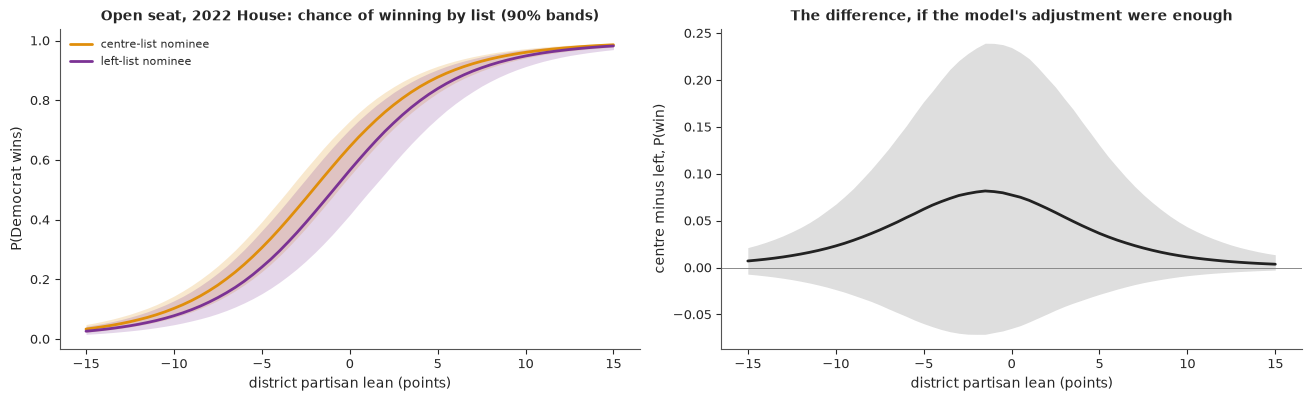

In [12]:
def win_curve(idata, leans, group="2022 H"):
    """P(the Democrat wins) for an open seat (no incumbent on either side) at each lean, by bucket,
    integrating the Student-t noise analytically."""
    p = idata.posterior
    a = p["a"].sel(group=group).to_numpy().ravel()
    bl = p["b_lean"].sel(cycle=int(group[:4])).to_numpy().ravel()
    tl, tc = (p["tau"].sel(bucket=b).to_numpy().ravel() for b in ("left", "centre"))
    s, nu = p["sigma"].to_numpy().ravel(), p["nu"].to_numpy().ravel()
    out = {}
    for b, t in (("left", tl), ("centre", tc)):
        mu = a[:, None] + bl[:, None] * leans[None, :] / 10 + t[:, None]
        out[b] = stats.t.cdf(mu / s[:, None], df=nu[:, None])
    return out


leans = np.arange(-15, 15.1, 0.5)
WC = win_curve(FITS["adjusted: nominee did not hold the seat"], leans)
dwin = WC["centre"] - WC["left"]
for L0 in (-5, 0, 5):
    j = int(np.argmin(np.abs(leans - L0)))
    print(f"open seat, lean {L0:+d}: P(win) centre {np.median(WC['centre'][:, j]):.2f}, left {np.median(WC['left'][:, j]):.2f}; "
          f"difference {np.median(dwin[:, j]):+.2f} (90% {np.quantile(dwin[:, j], 0.05):+.2f} to {np.quantile(dwin[:, j], 0.95):+.2f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
ax = axes[0]
for b, col in (("centre", CEN_C), ("left", LEFT_C)):
    ax.fill_between(leans, *np.quantile(WC[b], [0.05, 0.95], 0), color=col, alpha=0.2, lw=0)
    ax.plot(leans, np.median(WC[b], 0), color=col, lw=2, label=f"{b}-list nominee")
ax.set_xlabel("district partisan lean (points)")
ax.set_ylabel("P(Democrat wins)")
ax.legend(fontsize=8)
ax.set_title("Open seat, 2022 House: chance of winning by list (90% bands)", fontsize=10)
ax = axes[1]
ax.fill_between(leans, *np.quantile(dwin, [0.05, 0.95], 0), color=INK, alpha=0.15, lw=0)
ax.plot(leans, np.median(dwin, 0), color=INK, lw=2)
ax.axhline(0, color=MUTED, lw=0.7)
ax.set_xlabel("district partisan lean (points)")
ax.set_ylabel("centre minus left, P(win)")
ax.set_title("The difference, if the model's adjustment were enough", fontsize=10);

At a lean of zero, the model gives a centre-list nominee a 0.64 chance and a left-list nominee 0.57, a
difference of +0.08 (90% -0.06 to +0.23). Five points either side, the difference is +0.06 and +0.04, and
it fades in safe seats of either party, where the nominee changes little. The direction agrees with Hall's
and its size is far smaller, but all of it rests on the adjustment being enough. The next two sections ask
what happens when it is not.

## 5 · How strong would a hidden confounder have to be?

Suppose there is a confounder $U$ we did not measure, standardised to standard deviation 1. After the
adjustment, centre-list and left-list nominees differ in $U$ by $\delta$ standard deviations, and one
standard deviation of $U$ moves the margin by $\gamma$ points. Then the estimate has absorbed a bias of
about $\gamma\delta$, and the corrected contrast is $\Delta - \gamma\delta$. This is the omitted-variable
bias formula of regression; Cinelli and Hazlett (2020) develop a sharper version in terms of partial $R^2$.
The formula alone says nothing about which values of $\gamma$ and $\delta$ are plausible. To calibrate it,
we compute the same two numbers for confounders we did measure, among the nominees who did not hold the
seat, as if we had left them out: district lean and a Republican incumbent.

district lean : imbalance +0.42 sd, effect of 1 sd +21.0 points, implied bias if omitted +8.8 points
R incumbent   : imbalance -0.50 sd, effect of 1 sd -1.6 points, implied bias if omitted +0.8 points
contrast among nominees who did not hold the seat: median +1.1, 90% -1.0 to +3.4
a bias of +1.1 points moves the median to zero; -1.0 moves the lower end to zero; +3.4 the upper end
a confounder 10% as strong as lean (bias +0.9): corrected median +0.2, 90% -1.9 to +2.5
a confounder 25% as strong as lean (bias +2.2): corrected median -1.1, 90% -3.2 to +1.2
a confounder 50% as strong as lean (bias +4.4): corrected median -3.3, 90% -5.4 to -1.0


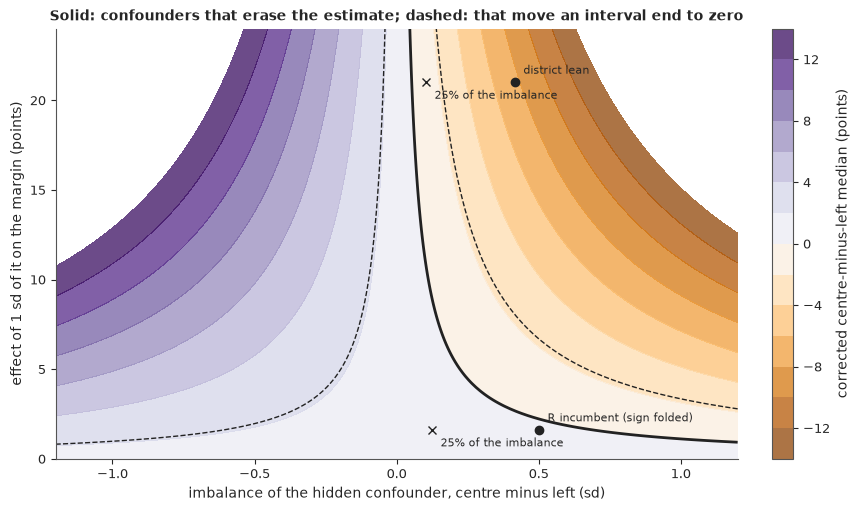

In [13]:
G = F[F.open_choice & F.bucket.isin(["left", "centre"])]
cen = (G.bucket == "centre").to_numpy()
post2 = FITS["adjusted: nominee did not hold the seat"].posterior
c2 = post2["contrast"].to_numpy().ravel()


def benchmark(v, coef):
    """Imbalance (centre minus left, in sd of v among these nominees) and effect of 1 sd of v on the margin."""
    sd = v.std()
    return (v[cen].mean() - v[~cen].mean()) / sd, coef * sd


bench = {"district lean": benchmark(G.lean.to_numpy(float) / 10, float(post2["b_lean"].mean())),
         "R incumbent": benchmark(G.r_inc.to_numpy(float), float(post2["beta"].sel(x="R incumbent").mean()))}
for k, (dl, gm) in bench.items():
    print(f"{k:14s}: imbalance {dl:+.2f} sd, effect of 1 sd {gm:+.1f} points, implied bias if omitted {dl * gm:+.1f} points")
print(f"contrast among nominees who did not hold the seat: median {np.median(c2):+.1f}, "
      f"90% {np.quantile(c2, 0.05):+.1f} to {np.quantile(c2, 0.95):+.1f}")
print(f"a bias of {np.median(c2):+.1f} points moves the median to zero; "
      f"{np.quantile(c2, 0.05):+.1f} moves the lower end to zero; {np.quantile(c2, 0.95):+.1f} the upper end")
for frac in (0.1, 0.25, 0.5):
    b = frac * bench["district lean"][0] * bench["district lean"][1]
    print(f"a confounder {frac:.0%} as strong as lean (bias {b:+.1f}): corrected median {np.median(c2 - b):+.1f}, "
          f"90% {np.quantile(c2 - b, 0.05):+.1f} to {np.quantile(c2 - b, 0.95):+.1f}")

dg = np.linspace(-1.2, 1.2, 121)
gg = np.linspace(0, 24, 121)
DG, GG = np.meshgrid(dg, gg)
med = np.median(c2) - DG * GG
lo, hi = np.quantile(c2, 0.05) - DG * GG, np.quantile(c2, 0.95) - DG * GG
fig, ax = plt.subplots(figsize=(8.5, 5))
cs = ax.contourf(DG, GG, med, levels=np.arange(-14, 15, 2), cmap="PuOr", alpha=0.75)
fig.colorbar(cs, ax=ax, label="corrected centre-minus-left median (points)")
ax.contour(DG, GG, med, levels=[0], colors=INK, linewidths=2)
ax.contour(DG, GG, lo, levels=[0], colors=INK, linewidths=1, linestyles="--")
ax.contour(DG, GG, hi, levels=[0], colors=INK, linewidths=1, linestyles="--")
for k, (dl, gm) in bench.items():
    sgn = np.sign(gm)
    ax.plot(dl * sgn, abs(gm), "o", color=INK)
    ax.annotate(k + (" (sign folded)" if sgn < 0 else ""), (dl * sgn, abs(gm)), textcoords="offset points",
                xytext=(6, 6), fontsize=8)
    for frac in (0.25,):
        ax.plot(frac * dl * sgn, abs(gm), "x", color=INK)
        ax.annotate(f"{frac:.0%} of the imbalance", (frac * dl * sgn, abs(gm)), textcoords="offset points",
                    xytext=(6, -12), fontsize=8)
ax.set_xlabel("imbalance of the hidden confounder, centre minus left (sd)")
ax.set_ylabel("effect of 1 sd of it on the margin (points)")
ax.set_title("Solid: confounders that erase the estimate; dashed: that move an interval end to zero", fontsize=10);

Among the 110 list nominees who did not hold the seat, centre-list nominees ran in districts 0.42 standard
deviations more Democratic, and a standard deviation of lean is worth 21 points of margin: leaving lean
out would bias the contrast by about 8.8 points. Facing a Republican incumbent is far weaker, a bias of 0.8.
The estimate itself is small by comparison. A bias of +1.1 points is enough to move its median to zero,
and a confounder with **a tenth of the bias of lean** nearly does it (corrected median +0.2, 90%
-1.9 to +2.5). A confounder a quarter as strong as lean in the same direction gives -1.1 (-3.2 to +1.2), and
one half as strong gives -3.3 (-5.4 to -1.0), a left advantage that excludes zero.

In the figure, the solid curve is the set of confounders that erase the median and the dashed curves the
ones that move an end of the interval to zero. The Republican incumbent is drawn with both signs flipped,
which leaves the product $\gamma\delta$ unchanged. Is a confounder of that size plausible? Candidate
quality is the obvious one: prior elected office, a fundraising network or recruitment by the party could
easily differ between the lists by a few tenths of a standard deviation and be worth a few points. Its sign
is not obvious either. Endorsers on the centre may favour candidates the party has recruited, while a
left-list challenger who won a contested primary has shown a local base. The data cannot rule out either.

## 6 · Simulated elections: a comparison that gets the sign wrong

A sensitivity analysis says how large a confounder would have to be. A simulation shows how naturally one
arises. We build elections in which we know the answer. Each world has 300 races whose leans are drawn from
the real races (those leaning more than 15 points Republican are left out). A centre-list nominee is chosen
with probability $1 / (1 + e^{0.04(\text{lean} - 12)})$, so the left list gets the safer seats. Each nominee
also has a hidden strength $q \sim N(\delta_q \cdot \text{centre}, 1)$ worth 3 points per standard deviation,
and the margin is

$$
m = 1 + \text{lean} + \tau \cdot \text{centre} + 3q + \varepsilon, \qquad \varepsilon \sim N(0, 7^2).
$$

The true effect $\tau$ is 0 or +3 (a left-list nominee costs 3 points). In the first world $q$ does not
depend on the list ($\delta_q = 0$); in the second, centre-list nominees are 0.6 standard deviations
stronger; in the third, left-list nominees are. We run 400 worlds of each kind and three estimators: the
difference in means, least squares with lean (the analogue of section 4), and least squares with lean and
$q$, which no real analyst has. Least squares stands in for the posterior mean here; with this much data
and weak priors the two agree closely, and it keeps the 2,400 fits fast.

one simulated world: mean lean of centre nominees 8.5, of left nominees 21.8; 130 centre, 170 left
                         world  true effect                      estimator  mean estimate  5% of worlds  95% of worlds  share below 0  share off by 2+ points
                     lean only          0.0            difference in means          -17.1         -21.0          -12.7           1.00                    1.00
                     lean only          0.0              adjusted for lean           -0.0          -1.4            1.5           0.51                    0.02
                     lean only          0.0 adjusted for lean and strength           -0.0          -1.4            1.3           0.53                    0.01
                     lean only          3.0            difference in means          -14.1         -18.0           -9.7           1.00                    1.00
                     lean only          3.0              adjusted for lean            3.0           1.6        

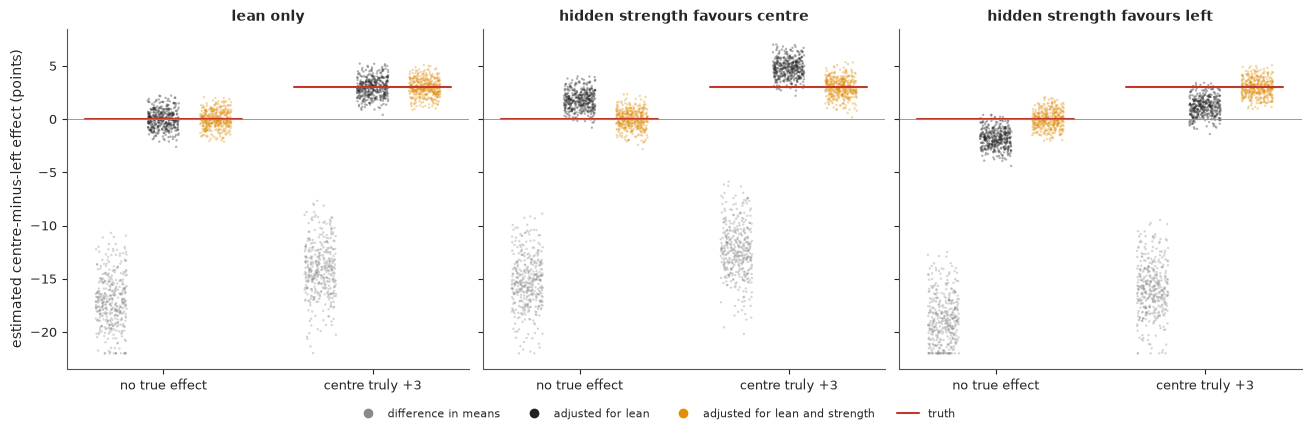

In [14]:
def simulate(n_worlds=400, n=300, effect=0.0, q_imbalance=0.0, q_effect=3.0, seed=RANDOM_SEED):
    """Elections in which a centre-list nominee truly changes the margin by `effect` points. Left-list
    nominees are chosen more often in safer seats; a hidden candidate-strength score q differs by
    `q_imbalance` sd between the buckets and is worth `q_effect` points per sd."""
    g = np.random.default_rng(seed)
    pool = F.lean.to_numpy(float)
    out = np.empty((n_worlds, 3))
    for w in range(n_worlds):
        lean = g.choice(pool[pool > -15], n)
        centre = g.random(n) < 1 / (1 + np.exp(0.04 * (lean - 12)))
        q = g.normal(q_imbalance * centre, 1.0)
        m = 1.0 + 1.0 * lean + effect * centre + q_effect * q + g.normal(0, 7.0, n)
        X1 = np.c_[np.ones(n), centre, lean]
        X2 = np.c_[X1, q]
        out[w] = (m[centre].mean() - m[~centre].mean(), np.linalg.lstsq(X1, m, rcond=None)[0][1],
                  np.linalg.lstsq(X2, m, rcond=None)[0][1])
    return out, lean, centre


SCEN = {"lean only": 0.0, "hidden strength favours centre": 0.6, "hidden strength favours left": -0.6}
sim_rows, SIM = [], {}
for sname, qi in SCEN.items():
    for eff in (0.0, 3.0):
        est, lean_last, cen_last = simulate(effect=eff, q_imbalance=qi)
        SIM[(sname, eff)] = est
        for j, ename in enumerate(("difference in means", "adjusted for lean", "adjusted for lean and strength")):
            sim_rows.append({"world": sname, "true effect": eff, "estimator": ename,
                             "mean estimate": round(est[:, j].mean(), 1),
                             "5% of worlds": round(np.quantile(est[:, j], 0.05), 1),
                             "95% of worlds": round(np.quantile(est[:, j], 0.95), 1),
                             "share below 0": round(float((est[:, j] < 0).mean()), 2),
                             "share off by 2+ points": round(float((np.abs(est[:, j] - eff) >= 2).mean()), 2)})
print(f"one simulated world: mean lean of centre nominees {lean_last[cen_last].mean():.1f}, "
      f"of left nominees {lean_last[~cen_last].mean():.1f}; {cen_last.sum()} centre, {(~cen_last).sum()} left")
print(pd.DataFrame(sim_rows).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, sname in zip(axes, SCEN):
    for i, eff in enumerate((0.0, 3.0)):
        est = SIM[(sname, eff)]
        for j, col in enumerate((MUTED, INK, CEN_C)):
            x = i * 4 + j
            v = np.clip(est[:, j], -22, 12)
            ax.scatter(x + rng.uniform(-0.3, 0.3, len(v)), v, s=3, color=col, alpha=0.35, edgecolor="none")
        ax.plot([i * 4 - 0.5, i * 4 + 2.5], [eff, eff], color=R_C, lw=1.5)
    ax.axhline(0, color=MUTED, lw=0.6)
    ax.set_xticks([1, 5], ["no true effect", "centre truly +3"])
    ax.set_title(sname, fontsize=10)
axes[0].set_ylabel("estimated centre-minus-left effect (points)")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=lab) for c, lab in
                        ((MUTED, "difference in means"), (INK, "adjusted for lean"), (CEN_C, "adjusted for lean and strength"))]
               + [Line2D([], [], color=R_C, label="truth")], fontsize=8, loc="outside lower center", ncol=4);

The selection rule puts centre-list nominees in seats leaning 8.5 points to the Democrats and left-list
nominees in seats leaning 21.8, close to the real 7.7 and 24.3. The difference in means is badly wrong in
every world: about -17 when there is no effect and -14 when the centre is truly 3 points better, and it is
below zero in effectively every world, including those where the centre is truly better. Adjusting for lean fixes that completely in the first world,
where lean is the only confounder (mean estimates -0.0 and 3.0).

The other two worlds are the lesson. When the centre-list nominees are hidden-stronger, the lean-adjusted
estimate is **+1.8 with no true effect**, between +0.4 and +3.3 in 90% of worlds and below zero in only 2%:
a confident centre advantage that does not exist, the same size as the estimate from the real data. When
the left-list nominees are hidden-stronger, a true 3-point centre advantage shows up as +1.2 and is below
zero in 8% of worlds. Only the estimator that sees $q$ recovers the truth, on average, in every kind of world. The real-data
estimate of +1.1 to +1.8 cannot tell "the centre list is worth about 2 points" from "the centre list's
nominees were stronger candidates by about half a standard deviation".

## 7 · What data would answer the question, and how much of it

Three kinds of design could answer the question, and each needs data the repository does not have.

**A close-primary regression discontinuity** (Hall 2015, after Lee 2008's design for close general
elections) is the strongest. Among Democratic primaries in which a centre candidate and a left candidate
were the top two, let $r$ be the centre candidate's primary vote margin over the left one. Just above
$r = 0$ the centre candidate is nominated, just below it the left one, and if nothing else jumps at zero,
the jump in the general-election margin estimates $\tau$ for races where both were real options, which is
exactly the conditional estimand of section 1. It needs, for every Democratic House and Senate primary of
the cycles used: the vote counts of every candidate (state certified primary results, or a compiled source
such as MIT's Election Data and Science Lab, whose coverage of primaries would need checking); an
ideology measure for **both** top candidates **dated before the primary**, not before the general, since the
lists captured in the autumn hold mostly winners; and the general-election results of those races, which
the repository has.

**Pre-election ideology scores for non-incumbents.** Lists only reach the candidates an organisation
chose to endorse, and roll-call scores only reach members. Scores estimated from campaign contributions,
such as Bonica's CFscores in the Database on Ideology, Money in Politics, and Elections (DIME; Bonica 2014),
exist for most candidates who raise money, losers included, and could place both primary candidates on one
scale. The CCES placements of section 2 are a voter-side alternative for the candidates who reached the
general election.

**District partisanship by district and all races.** The repository already has FiveThirtyEight's lean
for 2018 and 2022 and Cook's PVI for 2026. A design that pools more cycles needs a consistent measure
across redistricting, such as presidential two-party vote by congressional district (compiled by Daily Kos
Elections and by Dave's Redistricting). It also needs every race, not only the polled ones, which the
repository has for the general election.

Finally, **voter-level data**: the CES (formerly CCES) asks respondents to place their candidates and
records their vote, so a later analysis could ask whether voters who see a nominee as further from
themselves defect more. That speaks to the mechanism, not to the counterfactual nominee.

How many close primaries would the regression discontinuity need? We simulate it. Within 10 points of a
tie, the centre candidate's primary margin $r$ is uniform; the general-election margin is $\tau \cdot
\mathbb{1}[r > 0] + 0.3\,r + \varepsilon$, fitted by a local linear regression with separate slopes on each
side. The noise is the spread of real margins: 7.3 points around the adjusted fit among the 512 nominees
who did not hold the seat, if the analysis adjusts for lean, and 22.9 points if it does not. For $\tau$ we
take 2, 5 and 10 points of margin. That is a range, not an estimate: Hall's 9 to 13 points of vote share
is roughly 18 to 26 points on this margin scale, but it comes from other decades and a donor-based measure
of extremism, and there is no reason to assume it carries over to the lists used here.

In [15]:
G2 = F[F.open_choice]
post2 = FITS["adjusted: nominee did not hold the seat"].posterior
D2 = design(G2.reset_index(drop=True))
mu2 = (post2["a"].mean(("chain", "draw")).to_numpy()[D2["gi"]]
       + post2["b_lean"].mean(("chain", "draw")).to_numpy()[D2["ci"]] * D2["lean"]
       + sum(float(post2["beta"].sel(x=j).mean()) * v for j, v in D2["X"].items())
       + float(post2["tau"].sel(bucket="left").mean()) * D2["L"] + float(post2["tau"].sel(bucket="centre").mean()) * D2["C"])
SIG_ADJ = float(np.std(G2.m.to_numpy() - mu2))
SIG_RAW = float(G2.m.std())
print(f"nominees who did not hold the seat: {len(G2)}; sd of the margin {SIG_RAW:.1f} points, "
      f"sd around the adjusted fit {SIG_ADJ:.1f}")


def rd_power(n, sigma, effects=(2.0, 5.0, 10.0), h=10.0, slope=0.3, reps=2000, seed=RANDOM_SEED):
    """Close primaries between a centre-list and a left-list candidate: the running variable is the centre
    candidate's primary margin over the left one, uniform on (-h, h); a local linear fit with separate
    slopes. Returns the mean 90% interval width and, per effect, the share of intervals above zero."""
    g = np.random.default_rng(seed)
    r = g.uniform(-h, h, (reps, n))
    d = (r > 0).astype(float)
    X = np.stack([np.ones_like(r), d, r, d * r], -1)
    XtX_inv = np.linalg.inv(np.einsum("rni,rnj->rij", X, X))
    e = g.normal(0, sigma, (reps, n))
    res = {"width": None}
    for eff in effects:
        y = eff * d + slope * r + e
        b = np.einsum("rij,rnj,rn->ri", XtX_inv, X, y)
        s2 = ((y - np.einsum("rni,ri->rn", X, b)) ** 2).sum(1) / (n - 4)
        se = np.sqrt(s2 * XtX_inv[:, 1, 1])
        res[eff] = float(((b[:, 1] - 1.645 * se) > 0).mean())
        res["width"] = float((2 * 1.645 * se).mean())
    return res


NS = [25, 50, 100, 200, 400, 800, 1600]
pw = []
for lab_, sig in (("margin adjusted for lean", SIG_ADJ), ("raw margin", SIG_RAW)):
    for n in NS:
        r_ = rd_power(n, sig)
        pw.append({"outcome": lab_, "close primaries": n, "90% interval width": round(r_["width"], 1),
                   "P(exclude 0) if effect 2": round(r_[2.0], 2), "effect 5": round(r_[5.0], 2),
                   "effect 10": round(r_[10.0], 2)})
PW = pd.DataFrame(pw)
print(PW.to_string(index=False))

nominees who did not hold the seat: 512; sd of the margin 22.9 points, sd around the adjusted fit 7.3


                 outcome  close primaries  90% interval width  P(exclude 0) if effect 2  effect 5  effect 10
margin adjusted for lean               25                21.0                      0.10      0.21       0.47
margin adjusted for lean               50                14.1                      0.13      0.33       0.76
margin adjusted for lean              100                 9.8                      0.16      0.53       0.96
margin adjusted for lean              200                 6.9                      0.26      0.79       1.00
margin adjusted for lean              400                 4.8                      0.39      0.96       1.00
margin adjusted for lean              800                 3.4                      0.62      1.00       1.00
margin adjusted for lean             1600                 2.4                      0.85      1.00       1.00
              raw margin               25                66.1                      0.07      0.09       0.14
              raw m

With lean in the model, 100 close primaries give a 90% interval about 10 points wide, enough to detect a
10-point effect almost every time (0.96) and a 5-point effect half the time (0.53). A 5-point effect needs
about 200 close primaries for an 80% chance that the interval excludes zero, and the interval narrows below
5 points only at about 400. A 2-point effect needs about 1,600. Without the lean adjustment every number is
far worse: 800 close primaries for a 10-point effect. As a check that the least-squares widths are a fair
guide to a Bayesian analysis, we fit one simulated set of 100 close primaries in PyMC with weak priors.

{'divergences': 0, 'max r_hat': 1.002, 'min ESS': 862, 'tuning': 400}
one simulated set of 100 close primaries, true jump 5: posterior 90% interval +2.3 to +10.7 (width 8.5); least squares +2.5 to +11.4 (width 8.8)


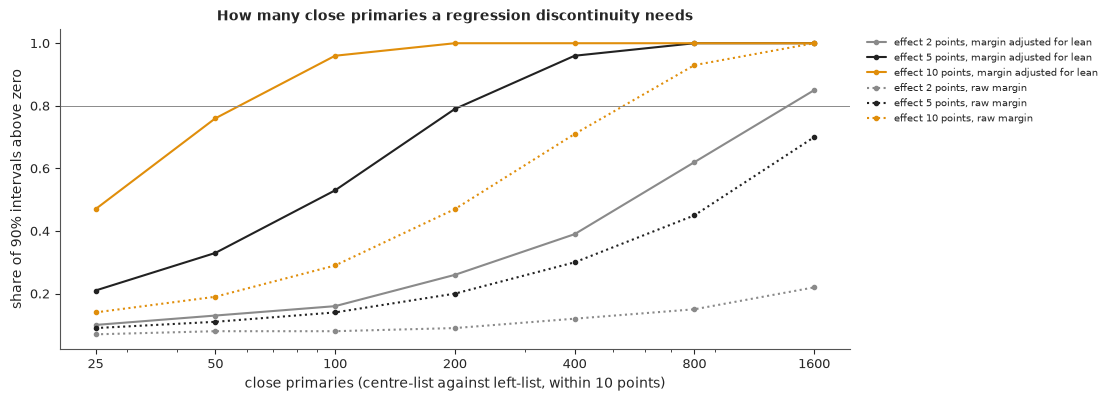

In [16]:
g = np.random.default_rng(RANDOM_SEED)
n_chk = 100
r_chk = g.uniform(-10, 10, n_chk)
d_chk = (r_chk > 0).astype(float)
y_chk = 5.0 * d_chk + 0.3 * r_chk + g.normal(0, SIG_ADJ, n_chk)
with pm.Model() as rd:
    a0 = pm.Normal("a0", 0, 20)
    jump = pm.Normal("jump", 0, 10)
    s_l = pm.Normal("slope_left", 0, 2)
    s_r = pm.Normal("slope_right", 0, 2)
    sig = pm.HalfNormal("sigma", 15)
    pm.Normal("y", a0 + jump * d_chk + s_l * r_chk * (1 - d_chk) + s_r * r_chk * d_chk, sig, observed=y_chk)
    idata_rd = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
j = idata_rd.posterior["jump"].to_numpy().ravel()
Xr = np.c_[np.ones(n_chk), d_chk, r_chk, d_chk * r_chk]
br, *_ = np.linalg.lstsq(Xr, y_chk, rcond=None)
se_r = np.sqrt(((y_chk - Xr @ br) ** 2).sum() / (n_chk - 4) * np.linalg.inv(Xr.T @ Xr)[1, 1])
print(diagnostics(idata_rd))
print(f"one simulated set of {n_chk} close primaries, true jump 5: posterior 90% interval "
      f"{np.quantile(j, 0.05):+.1f} to {np.quantile(j, 0.95):+.1f} (width {np.ptp(np.quantile(j, [0.05, 0.95])):.1f}); "
      f"least squares {br[1] - 1.645 * se_r:+.1f} to {br[1] + 1.645 * se_r:+.1f} (width {2 * 1.645 * se_r:.1f})")

fig, ax = plt.subplots(figsize=(11, 3.9))
for lab_, ls in (("margin adjusted for lean", "-"), ("raw margin", ":")):
    s = PW[PW.outcome == lab_]
    for col_, eff, colr in (("P(exclude 0) if effect 2", 2, MUTED), ("effect 5", 5, INK), ("effect 10", 10, CEN_C)):
        ax.plot(s["close primaries"], s[col_], ls, marker="o", ms=3, color=colr,
                label=f"effect {eff} points, {lab_}")
ax.axhline(0.8, color=MUTED, lw=0.7)
ax.set_xscale("log")
ax.set_xticks(NS, [str(n) for n in NS])
ax.set_xlabel("close primaries (centre-list against left-list, within 10 points)")
ax.set_ylabel("share of 90% intervals above zero")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set_title("How many close primaries a regression discontinuity needs", fontsize=10);

The posterior interval (+2.3 to +10.7, width 8.5) and the least-squares interval (width 8.8) agree, with no
divergences, so the power table carries over to the Bayesian version.

How many such primaries exist? The repository cannot count them: it has no primary results and no losing
candidates. It can bound them. In 2018 and 2022 together, 512 Democratic nominations went to someone who
did not hold the seat, and only some of those primaries had a centre candidate and a left candidate as the
top two, of which only some were within 10 points. Even if every one of the 512 qualified, it would fall
far short of the 1,600 needed for a 2-point effect. A 5-point effect needs about 200 close contests between
the two wings, which means pooling many cycles, as Hall pooled thirty years. And it means labels dated
before each primary, which the lists in E118 are not.

In [17]:
print(f"notebook ran in {time.time() - T_START:.0f} s")

notebook ran in 9 s


## Summary

* **The question is not E118's question.** E118 compared poll errors; a penalty that voters apply to a
  nominee shows up in the polls too, so a null on poll error is compatible with any effect on the margin.
  The counterfactual here is the margin, and the chance of winning, under a different nominee in the same
  race, among races where both kinds of candidate were on offer.
* **The repository has the outcome and the main confounder, and not the alternatives.** All 861 contested
  races of 2018 and 2022 have a certified margin and a partisan lean, and only 308 were polled. There are
  no primary results, no rows for primary losers (49 of 79 names on the 2018 Justice Democrats list match
  no nominee), no roll-call score for any of the nominees who had not served, and the autumn captures of
  Our Revolution, the Blue Dog PAC and the NewDem Action Fund list winners almost exclusively. In the 2018
  CCES, voters place left-list and centre-list nominees only 0.11 points apart on a seven-point scale.
* **The raw comparison follows the districts.** Left-list nominees won by 16 points more than centre-list
  nominees, because they ran in districts 17 points more Democratic; among non-incumbents the sign flips.
* **The best available adjustment gives a small centre edge that the data cannot defend.** With lean,
  incumbency and cycle, the centre-minus-left contrast is +1.8 points (90% +0.6 to +3.0) on all races and
  +1.1 (-1.0 to +3.4) among nominees who did not hold the seat, about +0.08 in the chance of winning an
  even open seat. A confounder with a tenth of the bias of lean all but erases it, and half reverses it.
  Both lists beat no-list nominees, a sign that the labels carry candidate quality.
* **A reasonable adjustment can manufacture this result.** In simulated elections where centre-list
  nominees are 0.6 standard deviations stronger candidates and the list does nothing, adjusting for lean
  finds +1.8 points, above zero in 98% of worlds.
* **The question can be answered, with other data.** A close-primary regression discontinuity needs primary
  results for every Democratic primary, ideology for both leading candidates dated before the primary (for
  example donor-based scores), and the general-election results. It needs about 200 close centre-against-left
  primaries to detect a 5-point effect and about 1,600 for 2 points; two cycles hold at most 512 open
  nominations of any kind. With the data available here, the answer is: not credibly.

## Try it yourself

1. **Use what voters see.** Replace the lists with the 2018 CCES placement of each Democratic nominee
   (centred on the district's placement of the Republican, or on the respondents' own `ideo5`) as a
   continuous treatment, refit section 4 on 2018, and redo section 5 for a one-point shift in placement.
   Does the sensitivity look any better?
2. **Is money a confounder or a consequence?** Add the nominees' receipts by the eve (`d_rec_eve` in
   `e94_races`) to the adjusted model. Draw where it belongs in the graph, explain whether the contrast
   that results is closer to or further from $\tau$, and say what you would need to know to decide.
3. **A sharper power analysis.** Change the simulation of section 7: a bandwidth of 5 or 20 points instead
   of 10, more weight near zero (a triangular kernel), and an effect that shrinks in safe seats as the
   win-probability curve of section 4 suggests. How many close primaries does a 5-point effect need now,
   and how much does the answer depend on the share of primaries that are close?